In [ ]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from typing import Dict, List, Tuple
import warnings
warnings.filterwarnings('ignore')


# ============================================================================
# PART 1: HEALTH SCORE CALCULATION
# ============================================================================

def calculate_health_score(age_years: float, design_life: float,
                           solar_current: float, battery_voltage: float,
                           temperature: float, memory_errors: int,
                           resets: int) -> float:
    """Calculate health score based on age and degradation"""

    age_ratio = age_years / design_life

    if age_ratio < 0.4:
        age_score = 100 - age_ratio * 30
    elif age_ratio < 0.7:
        age_score = 88 - (age_ratio - 0.4) * 80
    elif age_ratio < 1.0:
        age_score = 64 - (age_ratio - 0.7) * 90
    elif age_ratio < 1.3:
        age_score = 37 - (age_ratio - 1.0) * 73
    else:
        age_score = 15 - (age_ratio - 1.3) * 25

    solar_score = max(0, min(100, (solar_current / 20.0) * 100))
    battery_score = max(0, min(100, (battery_voltage / 28.0) * 100))

    if temperature < 35:
        temp_score = 100
    elif temperature < 45:
        temp_score = 100 - (temperature - 35) * 8
    else:
        temp_score = max(0, 60 - (temperature - 45) * 6)

    error_score = max(0, 100 - min(100, memory_errors / 1000))
    reset_score = max(0, 100 - min(100, resets * 5))

    health_score = (
        0.30 * age_score + 0.20 * solar_score + 0.20 * battery_score +
        0.15 * temp_score + 0.08 * error_score + 0.07 * reset_score
    )

    return round(max(0, min(100, health_score)), 1)


def assign_label_by_health_score(health_score: float) -> str:
    if health_score >= 85:
        return 'Healthy'
    elif health_score >= 65:
        return 'Monitor'
    elif health_score >= 40:
        return 'Degrading'
    elif health_score >= 20:
        return 'Critical'
    else:
        return 'Disposal Recommended'


# ============================================================================
# PART 2: DEGRADATION MODEL (Common for all types)
# ============================================================================

def get_degradation_factors(age_years: float, design_life: float) -> Dict:
    age_ratio = age_years / design_life

    if age_ratio < 1.0:
        solar_factor = 1.0 - 0.03 * age_years
        voltage_drift = age_ratio * 3
        temp_offset = age_ratio * 15
    else:
        solar_factor = max(0.01, 0.70 - 0.35 * (age_ratio - 1.0))
        voltage_drift = 3.0 + (age_ratio - 1.0) * 8
        temp_offset = 15.0 + (age_ratio - 1.0) * 25

    if age_ratio < 0.8:
        battery_factor = 1.0 - 0.04 * age_years
    else:
        battery_factor = max(0.01, 0.68 - 0.45 * (age_ratio - 0.8))

    error_mult = min(200, np.exp(3.0 * age_ratio))

    if age_ratio < 1.0:
        reset_mult = 1 + 3 * age_ratio
    else:
        reset_mult = 4 + 10 * (age_ratio - 1.0)

    return {
        'solar_factor': max(0.01, min(1.0, solar_factor)),
        'battery_factor': max(0.01, min(1.0, battery_factor)),
        'voltage_drift': min(12.0, voltage_drift),
        'temp_offset': min(40.0, temp_offset),
        'error_mult': min(200, error_mult),
        'reset_mult': min(50, reset_mult)
    }


# ============================================================================
# PART 3: ORBIT-SPECIFIC GENERATORS
# ============================================================================

class LEOGenerator:
    """LEO: 400-1500 km, 90-120 min period, SAA passage"""

    R_E = 6371
    GM_E = 398600
    NOMINAL_VOLTAGE = 28.0
    NOMINAL_TEMPERATURE = 20.0
    DESIGN_LIFE = 7

    @classmethod
    def orbital_period(cls, altitude_km: float) -> float:
        a = cls.R_E + altitude_km
        period_s = 2 * np.pi * np.sqrt(a**3 / cls.GM_E)
        return period_s / 60

    @classmethod
    def generate(cls, satellite_id: str, launch_date: datetime,
                 current_date: datetime, num_days: int = 30,
                 interval_minutes: int = 60) -> List[Dict]:

        num_samples = num_days * 24 * 60 // interval_minutes
        timestamps = []
        for i in range(num_samples):
            timestamps.append(current_date - timedelta(minutes=i * interval_minutes))
        timestamps.reverse()

        altitude_km = np.random.uniform(400, 1500)
        period_min = cls.orbital_period(altitude_km)

        total_memory_errors = 0
        total_resets = 0
        telemetry_series = []
        start_ref = datetime(2024, 1, 1)

        for ts in timestamps:
            age_years = (ts - launch_date).days / 365.25
            deg = get_degradation_factors(age_years, cls.DESIGN_LIFE)

            # LEO: 90-min cycle, SAA passage
            t_orbit = (ts - start_ref).total_seconds() / 60
            orbital_phase = np.sin(2 * np.pi * (t_orbit % period_min) / period_min)
            in_saa = (ts.minute % 60) < 6  # SAA: ~10% of orbit
            in_eclipse = orbital_phase < -0.5
            dt_days = interval_minutes / (24 * 60)

            # Generate telemetry
            bus_voltage = cls.NOMINAL_VOLTAGE - deg['voltage_drift'] + np.random.normal(0, 0.05)
            base_current = 18.0
            current_factor = (deg['solar_factor'] + deg['battery_factor']) / 2
            bus_current = base_current * (1 + 0.5 * orbital_phase) * (0.7 + 0.3 * current_factor)
            bus_current += np.random.normal(0, base_current * 0.05)
            temperature = cls.NOMINAL_TEMPERATURE + 15 * orbital_phase + deg['temp_offset'] + np.random.normal(0, 3)
            incidence = 0.6 + 0.4 * (1 + orbital_phase)
            solar_current = 20.0 * incidence * deg['solar_factor'] + np.random.normal(0, 0.2)
            battery_voltage = 28.0 * deg['battery_factor'] - 0.5 * (1 - deg['battery_factor']) - (0.5 if in_eclipse else 0)
            battery_voltage += np.random.normal(0, 0.3)
            battery_temp = temperature + np.random.normal(0, 2) + (1 - deg['battery_factor']) * 5

            R_bg = 2.18e-5
            R_saa = 3.05e-4
            error_rate = (R_bg + (R_saa if in_saa else 0)) * deg['error_mult']
            new_errors = np.random.poisson(error_rate * dt_days)
            total_memory_errors += new_errors

            base_resets_per_month = 0.1
            resets_per_month = base_resets_per_month * deg['reset_mult'] + (2 if in_saa else 0)
            resets_per_day = resets_per_month / 30.44
            new_resets = np.random.poisson(resets_per_day * dt_days)
            total_resets += new_resets

            decay_rate = np.random.uniform(0.1, 1.0)
            altitude = altitude_km - decay_rate * min(age_years, cls.DESIGN_LIFE) + np.random.normal(0, 0.03)

            health_score = calculate_health_score(
                age_years, cls.DESIGN_LIFE, solar_current, battery_voltage,
                temperature, total_memory_errors, total_resets
            )
            health_label = assign_label_by_health_score(health_score)

            telemetry_series.append({
                'satellite_id': satellite_id,
                'launch_timestamp': launch_date,
                'timestamp': ts,
                'orbit_type': 'LEO',
                'bus_voltage_v': round(min(35.0, max(15.0, bus_voltage)), 2),
                'bus_current_a': round(max(0.5, bus_current), 2),
                'temperature_c': round(temperature, 1),
                'solar_current_a': round(max(0, solar_current), 2),
                'battery_voltage_v': round(min(32.0, max(20.0, battery_voltage)), 2),
                'battery_temp_c': round(battery_temp, 1),
                'memory_errors_total': total_memory_errors,
                'reset_counter_total': total_resets,
                'altitude_km': round(max(300, altitude), 0),
                'orbital_phase': round(orbital_phase, 3),
                'health_score': health_score,
                'health_label': health_label
            })

        return telemetry_series


class GEOGenerator:
    """GEO: 35,786 km, 24-hour period, eclipse seasons only"""

    NOMINAL_VOLTAGE = 70.0
    NOMINAL_TEMPERATURE = 20.0
    DESIGN_LIFE = 15

    @classmethod
    def eclipse_season(cls, day_of_year: int) -> bool:
        """GEO: Eclipses only during equinox seasons (92 days/year)"""
        return (58 <= day_of_year <= 102) or (263 <= day_of_year <= 308)

    @classmethod
    def generate(cls, satellite_id: str, launch_date: datetime,
                 current_date: datetime, num_days: int = 30,
                 interval_minutes: int = 60) -> List[Dict]:

        num_samples = num_days * 24 * 60 // interval_minutes
        timestamps = []
        for i in range(num_samples):
            timestamps.append(current_date - timedelta(minutes=i * interval_minutes))
        timestamps.reverse()

        altitude_km = 35786.0
        total_memory_errors = 0
        total_resets = 0
        telemetry_series = []

        for ts in timestamps:
            age_years = (ts - launch_date).days / 365.25
            deg = get_degradation_factors(age_years, cls.DESIGN_LIFE)

            # GEO: 24-hour cycle, eclipse only in seasons
            orbital_phase = (ts.hour + ts.minute/60) / 24
            day_of_year = ts.timetuple().tm_yday
            in_eclipse = cls.eclipse_season(day_of_year) and (orbital_phase < 0.1 or orbital_phase > 0.9)
            dt_days = interval_minutes / (24 * 60)

            bus_voltage = cls.NOMINAL_VOLTAGE - deg['voltage_drift'] * 0.5 + np.random.normal(0, 0.7)
            base_current = 25.0
            current_factor = (deg['solar_factor'] + deg['battery_factor']) / 2
            bus_current = base_current * (1 + 0.15 * orbital_phase) * (0.7 + 0.3 * current_factor)
            bus_current += np.random.normal(0, 2)

            temperature = 15 + 10 * np.sin(2 * np.pi * orbital_phase) + deg['temp_offset'] * 0.5 + np.random.normal(0, 2)
            temperature = np.clip(temperature, 0, 35)

            if in_eclipse:
                solar_current = 0
            else:
                incidence = 0.95 + 0.05 * np.sin(2 * np.pi * orbital_phase)
                solar_current = 30.0 * incidence * deg['solar_factor'] + np.random.normal(0, 0.5)

            battery_voltage = 70.0 * deg['battery_factor'] + np.random.normal(0, 0.5)
            battery_temp = temperature + np.random.normal(0, 2)

            error_rate = 1e-5 * deg['error_mult']
            new_errors = np.random.poisson(error_rate * dt_days)
            total_memory_errors += new_errors

            resets_per_day = (0.05 + 0.3 * (age_years / cls.DESIGN_LIFE)) / 30.44
            new_resets = np.random.poisson(resets_per_day * dt_days)
            total_resets += new_resets

            health_score = calculate_health_score(
                age_years, cls.DESIGN_LIFE, solar_current, battery_voltage,
                temperature, total_memory_errors, total_resets
            )
            health_label = assign_label_by_health_score(health_score)

            telemetry_series.append({
                'satellite_id': satellite_id,
                'launch_timestamp': launch_date,
                'timestamp': ts,
                'orbit_type': 'GEO',
                'bus_voltage_v': round(bus_voltage, 2),
                'bus_current_a': round(bus_current, 2),
                'temperature_c': round(temperature, 1),
                'solar_current_a': round(solar_current, 2),
                'battery_voltage_v': round(battery_voltage, 2),
                'battery_temp_c': round(battery_temp, 1),
                'memory_errors_total': total_memory_errors,
                'reset_counter_total': total_resets,
                'altitude_km': altitude_km,
                'orbital_phase': round(orbital_phase, 3),
                'health_score': health_score,
                'health_label': health_label
            })

        return telemetry_series


class MEOGenerator:
    """MEO: 5,000-20,000 km, Van Allen belt crossing"""

    R_E = 6371
    GM_E = 398600
    NOMINAL_VOLTAGE = 50.0
    NOMINAL_TEMPERATURE = 0.0
    DESIGN_LIFE = 12

    @classmethod
    def orbital_period(cls, altitude_km: float) -> float:
        a = cls.R_E + altitude_km
        period_s = 2 * np.pi * np.sqrt(a**3 / cls.GM_E)
        return period_s / 3600  # hours

    @classmethod
    def in_van_allen_belt(cls, altitude_km: float) -> bool:
        """MEO: Passes through inner Van Allen belt"""
        return 1000 <= altitude_km <= 15000

    @classmethod
    def generate(cls, satellite_id: str, launch_date: datetime,
                 current_date: datetime, num_days: int = 30,
                 interval_minutes: int = 60) -> List[Dict]:

        num_samples = num_days * 24 * 60 // interval_minutes
        timestamps = []
        for i in range(num_samples):
            timestamps.append(current_date - timedelta(minutes=i * interval_minutes))
        timestamps.reverse()

        altitude_km = np.random.uniform(5000, 20000)
        period_hr = cls.orbital_period(altitude_km)
        in_belt = cls.in_van_allen_belt(altitude_km)

        total_memory_errors = 0
        total_resets = 0
        telemetry_series = []
        start_ref = datetime(2024, 1, 1)

        for ts in timestamps:
            age_years = (ts - launch_date).days / 365.25
            deg = get_degradation_factors(age_years, cls.DESIGN_LIFE)

            # MEO: Hours-long period, constant radiation if in belt
            t_orbit = (ts - start_ref).total_seconds() / 3600
            orbital_phase = (t_orbit % period_hr) / period_hr
            dt_days = interval_minutes / (24 * 60)

            bus_voltage = cls.NOMINAL_VOLTAGE - deg['voltage_drift'] * 0.8 + np.random.normal(0, 0.5)
            base_current = 20.0
            current_factor = (deg['solar_factor'] + deg['battery_factor']) / 2
            bus_current = base_current * (1 + 0.2 * orbital_phase) * (0.7 + 0.3 * current_factor)
            bus_current += np.random.normal(0, 1)

            temperature = -0.001 * (altitude_km - 5000) + 30 * np.sin(2 * np.pi * orbital_phase)
            temperature += deg['temp_offset'] * 0.7 + np.random.normal(0, 5)

            incidence = 0.7 + 0.3 * orbital_phase
            solar_current = 20.0 * incidence * deg['solar_factor'] + np.random.normal(0, 0.5)

            battery_voltage = 28.0 * deg['battery_factor'] + np.random.normal(0, 0.3)
            battery_temp = temperature + np.random.normal(0, 2)

            # MEO: Higher error rate in Van Allen belt
            R_bg, R_belt = 1e-5, 1e-3
            error_rate = (R_bg + (R_belt if in_belt else 0)) * deg['error_mult']
            new_errors = np.random.poisson(error_rate * dt_days)
            total_memory_errors += new_errors

            resets_per_day = (0.1 + 0.5 * (age_years / cls.DESIGN_LIFE) + (2 if in_belt else 0)) / 30.44
            new_resets = np.random.poisson(resets_per_day * dt_days)
            total_resets += new_resets

            health_score = calculate_health_score(
                age_years, cls.DESIGN_LIFE, solar_current, battery_voltage,
                temperature, total_memory_errors, total_resets
            )
            health_label = assign_label_by_health_score(health_score)

            telemetry_series.append({
                'satellite_id': satellite_id,
                'launch_timestamp': launch_date,
                'timestamp': ts,
                'orbit_type': 'MEO',
                'bus_voltage_v': round(bus_voltage, 2),
                'bus_current_a': round(bus_current, 2),
                'temperature_c': round(temperature, 1),
                'solar_current_a': round(solar_current, 2),
                'battery_voltage_v': round(battery_voltage, 2),
                'battery_temp_c': round(battery_temp, 1),
                'memory_errors_total': total_memory_errors,
                'reset_counter_total': total_resets,
                'altitude_km': round(altitude_km, 0),
                'orbital_phase': round(orbital_phase, 3),
                'health_score': health_score,
                'health_label': health_label
            })

        return telemetry_series


class HEOGenerator:
    """HEO: Highly elliptical, 500-39,000 km, radiation belt crossing"""

    R_E = 6371
    PERIGEE = 500 + R_E
    APOGEE = 39000 + R_E
    ECC = 0.74
    NOMINAL_VOLTAGE = 50.0
    DESIGN_LIFE = 8

    @classmethod
    def altitude_at_anomaly(cls, true_anomaly_deg: float) -> float:
        a = (cls.PERIGEE + cls.APOGEE) / 2
        θ = np.radians(true_anomaly_deg)
        r = a * (1 - cls.ECC**2) / (1 + cls.ECC * np.cos(θ))
        return r - cls.R_E

    @classmethod
    def generate(cls, satellite_id: str, launch_date: datetime,
                 current_date: datetime, num_days: int = 30,
                 interval_minutes: int = 60) -> List[Dict]:

        num_samples = num_days * 24 * 60 // interval_minutes
        timestamps = []
        for i in range(num_samples):
            timestamps.append(current_date - timedelta(minutes=i * interval_minutes))
        timestamps.reverse()

        total_memory_errors = 0
        total_resets = 0
        telemetry_series = []
        start_ref = datetime(2024, 1, 1)
        period_hr = 12  # Molniya orbit

        for ts in timestamps:
            age_years = (ts - launch_date).days / 365.25
            deg = get_degradation_factors(age_years, cls.DESIGN_LIFE)

            # HEO: Altitude varies dramatically with true anomaly
            t_hours = (ts - start_ref).total_seconds() / 3600
            true_anomaly = (t_hours % period_hr) / period_hr * 360
            orbital_phase = true_anomaly / 360
            altitude_km = cls.altitude_at_anomaly(true_anomaly)
            in_belt = 1000 <= altitude_km <= 15000
            dt_days = interval_minutes / (24 * 60)

            bus_voltage = cls.NOMINAL_VOLTAGE - deg['voltage_drift'] + np.random.normal(0, 2)
            base_current = 20.0
            current_factor = (deg['solar_factor'] + deg['battery_factor']) / 2
            bus_current = base_current * (1 + 0.4 * orbital_phase) * (0.7 + 0.3 * current_factor)
            bus_current += np.random.normal(0, 2)

            temp_perigee, temp_apogee = 40, -50
            temperature = temp_perigee - (temp_perigee - temp_apogee) * ((altitude_km - 500) / (39000 - 500))
            temperature += deg['temp_offset'] + np.random.normal(0, 5)

            r_au = (altitude_km + cls.R_E) / 149597870
            solar_current = 25.0 * (1 / r_au**2) * deg['solar_factor'] + np.random.normal(0, 0.1)

            battery_voltage = 50.0 * deg['battery_factor'] + np.random.normal(0, 0.5)
            battery_temp = temperature + np.random.normal(0, 3)

            R_bg, R_belt = 1e-5, 5e-4
            error_rate = (R_bg + (R_belt if in_belt else 0)) * deg['error_mult']
            new_errors = np.random.poisson(error_rate * dt_days)
            total_memory_errors += new_errors

            if in_belt:
                resets_per_day = 8 / 365.25
            else:
                resets_per_day = 2 / 365.25
            new_resets = np.random.poisson(resets_per_day * dt_days)
            total_resets += new_resets

            health_score = calculate_health_score(
                age_years, cls.DESIGN_LIFE, solar_current, battery_voltage,
                temperature, total_memory_errors, total_resets
            )
            health_label = assign_label_by_health_score(health_score)

            telemetry_series.append({
                'satellite_id': satellite_id,
                'launch_timestamp': launch_date,
                'timestamp': ts,
                'orbit_type': 'HEO',
                'bus_voltage_v': round(bus_voltage, 2),
                'bus_current_a': round(bus_current, 2),
                'temperature_c': round(temperature, 1),
                'solar_current_a': round(max(0, solar_current), 2),
                'battery_voltage_v': round(battery_voltage, 2),
                'battery_temp_c': round(battery_temp, 1),
                'memory_errors_total': total_memory_errors,
                'reset_counter_total': total_resets,
                'altitude_km': round(altitude_km, 0),
                'orbital_phase': round(orbital_phase, 3),
                'health_score': health_score,
                'health_label': health_label
            })

        return telemetry_series


class SSOGenerator:
    """SSO: Sun-synchronous, 500-800 km, consistent sun angle"""

    R_E = 6371
    GM_E = 398600
    NOMINAL_VOLTAGE = 28.0
    NOMINAL_TEMPERATURE = 15.0
    DESIGN_LIFE = 7

    @classmethod
    def orbital_period(cls, altitude_km: float) -> float:
        a = cls.R_E + altitude_km
        period_s = 2 * np.pi * np.sqrt(a**3 / cls.GM_E)
        return period_s / 60

    @classmethod
    def generate(cls, satellite_id: str, launch_date: datetime,
                 current_date: datetime, num_days: int = 30,
                 interval_minutes: int = 60) -> List[Dict]:

        num_samples = num_days * 24 * 60 // interval_minutes
        timestamps = []
        for i in range(num_samples):
            timestamps.append(current_date - timedelta(minutes=i * interval_minutes))
        timestamps.reverse()

        altitude_km = np.random.uniform(500, 800)
        period_min = cls.orbital_period(altitude_km)

        total_memory_errors = 0
        total_resets = 0
        telemetry_series = []
        start_ref = datetime(2024, 1, 1)

        for ts in timestamps:
            age_years = (ts - launch_date).days / 365.25
            deg = get_degradation_factors(age_years, cls.DESIGN_LIFE)

            # SSO: Consistent sun angle, gradual precession
            t_orbit = (ts - start_ref).total_seconds() / 60
            orbital_phase = (t_orbit % period_min) / period_min
            day_of_year = ts.timetuple().tm_yday
            dt_days = interval_minutes / (24 * 60)

            bus_voltage = cls.NOMINAL_VOLTAGE - deg['voltage_drift'] + np.random.normal(0, 0.1)
            base_current = 18.0
            current_factor = (deg['solar_factor'] + deg['battery_factor']) / 2
            bus_current = base_current * (1 + 0.3 * orbital_phase) * (0.7 + 0.3 * current_factor)
            bus_current += np.random.normal(0, 1)

            temperature = -10 + 25 * np.sin(2 * np.pi * orbital_phase) + deg['temp_offset'] + np.random.normal(0, 2)

            # SSO: Exponential degradation + seasonal variation
            solar_degraded = 20.0 * np.exp(-1.034e-5 * age_years * 365.25)
            seasonal = 1 + 0.08 * np.cos(2 * np.pi * day_of_year / 365.25)
            solar_current = solar_degraded * seasonal * (0.7 + 0.3 * orbital_phase) + np.random.normal(0, 0.2)

            battery_voltage = 28.0 * deg['battery_factor'] + np.random.normal(0, 0.3)
            battery_temp = temperature + 2

            error_rate = 1e-5 * deg['error_mult']
            new_errors = np.random.poisson(error_rate * dt_days)
            total_memory_errors += new_errors

            resets_per_day = (0.1 + 0.5 * (age_years / cls.DESIGN_LIFE)) / 30.44
            new_resets = np.random.poisson(resets_per_day * dt_days)
            total_resets += new_resets

            health_score = calculate_health_score(
                age_years, cls.DESIGN_LIFE, solar_current, battery_voltage,
                temperature, total_memory_errors, total_resets
            )
            health_label = assign_label_by_health_score(health_score)

            telemetry_series.append({
                'satellite_id': satellite_id,
                'launch_timestamp': launch_date,
                'timestamp': ts,
                'orbit_type': 'SSO',
                'bus_voltage_v': round(bus_voltage, 2),
                'bus_current_a': round(bus_current, 2),
                'temperature_c': round(temperature, 1),
                'solar_current_a': round(max(0, solar_current), 2),
                'battery_voltage_v': round(battery_voltage, 2),
                'battery_temp_c': round(battery_temp, 1),
                'memory_errors_total': total_memory_errors,
                'reset_counter_total': total_resets,
                'altitude_km': round(altitude_km, 0),
                'orbital_phase': round(orbital_phase, 3),
                'health_score': health_score,
                'health_label': health_label
            })

        return telemetry_series


# ============================================================================
# PART 4: MAIN DATASET GENERATION
# ============================================================================

def generate_complete_dataset(num_per_type: int = 150, num_days: int = 30,
                               interval_minutes: int = 60) -> pd.DataFrame:

    generators = {
        'LEO': LEOGenerator,
        'SSO': SSOGenerator,
        'MEO': MEOGenerator,
        'GEO': GEOGenerator,
        'HEO': HEOGenerator
    }

    all_telemetry = []
    current_date = datetime(2024, 1, 15, 12, 0, 0)

    print("=" * 80)
    print("ORBITCYCLE - PHYSICS-BASED DATASET GENERATION")
    print("=" * 80)
    print(f"Satellites per orbit type: {num_per_type}")
    print(f"Total satellites: {num_per_type * 5}")
    print(f"Current date: {current_date.strftime('%Y-%m-%d')}")

    age_groups = [(1, 'Healthy'), (4, 'Monitor'), (7, 'Degrading'), (11, 'Critical'), (16, 'Disposal Recommended')]

    for orbit_type, generator in generators.items():
        print(f"\n📡 Generating {orbit_type} satellites...")
        design_life = generator.DESIGN_LIFE

        for i in range(num_per_type):
            if (i + 1) % 30 == 0:
                print(f"  Progress: {i+1}/{num_per_type}")

            age_group_idx = i % 5
            age_years, expected_label = age_groups[age_group_idx]

            if expected_label == 'Degrading':
                age_years = design_life - 1
            elif expected_label == 'Critical':
                age_years = design_life + 3
            elif expected_label == 'Disposal Recommended':
                age_years = design_life + 8

            age_years += np.random.uniform(-0.5, 0.5)
            age_years = max(0.5, age_years)

            launch_date = current_date - timedelta(days=age_years * 365.25)
            satellite_id = f"{orbit_type}-{i+1:04d}"

            telemetry = generator.generate(
                satellite_id, launch_date, current_date,
                num_days, interval_minutes
            )
            all_telemetry.extend(telemetry)

        print(f"  ✅ Completed {num_per_type} satellites")

    df = pd.DataFrame(all_telemetry)
    return df


if __name__ == "__main__":

    df = generate_complete_dataset(num_per_type=150, num_days=30, interval_minutes=60)

    output_file = 'orbitcycle_physics_based.csv'
    df.to_csv(output_file, index=False)

    print("\n" + "=" * 80)
    print("DATASET GENERATION COMPLETE")
    print("=" * 80)
    print(f"✅ Saved to: {output_file}")
    print(f"📊 Total rows: {len(df):,}")

    print("\n📊 Label distribution:")
    for label in ['Healthy', 'Monitor', 'Degrading', 'Critical', 'Disposal Recommended']:
        count = len(df[df['health_label'] == label])
        pct = count / len(df) * 100
        print(f"  {label}: {count:,} ({pct:.1f}%)")

    print("\n📊 Orbit type distribution:")
    for orbit in df['orbit_type'].unique():
        count = len(df[df['orbit_type'] == orbit])
        print(f"  {orbit}: {count:,} samples")

ORBITCYCLE - PHYSICS-BASED DATASET GENERATION
Satellites per orbit type: 150
Total satellites: 750
Current date: 2024-01-15

📡 Generating LEO satellites...
  Progress: 30/150
  Progress: 60/150
  Progress: 90/150
  Progress: 120/150
  Progress: 150/150
  ✅ Completed 150 satellites

📡 Generating SSO satellites...
  Progress: 30/150
  Progress: 60/150
  Progress: 90/150
  Progress: 120/150
  Progress: 150/150
  ✅ Completed 150 satellites

📡 Generating MEO satellites...
  Progress: 30/150
  Progress: 60/150
  Progress: 90/150
  Progress: 120/150
  Progress: 150/150
  ✅ Completed 150 satellites

📡 Generating GEO satellites...
  Progress: 30/150
  Progress: 60/150
  Progress: 90/150
  Progress: 120/150
  Progress: 150/150
  ✅ Completed 150 satellites

📡 Generating HEO satellites...
  Progress: 30/150
  Progress: 60/150
  Progress: 90/150
  Progress: 120/150
  Progress: 150/150
  ✅ Completed 150 satellites

DATASET GENERATION COMPLETE
✅ Saved to: orbitcycle_physics_based.csv
📊 Total rows: 54

Using device: cpu
ORBITCYCLE - PYTORCH CLASSIFIER (.pth)

Loaded 540,000 samples

Label distribution:
  Healthy: 194,547 (36.0%)
  Monitor: 166,039 (30.7%)
  Degrading: 132,750 (24.6%)
  Critical: 41,908 (7.8%)
  Disposal Recommended: 4,756 (0.9%)

Features: 15 columns
Classes: ['Critical', 'Degrading', 'Disposal Recommended', 'Healthy', 'Monitor']

Data split:
  Training: 367,200
  Validation: 64,800
  Test: 108,000

TRAINING PYTORCH CLASSIFIER

Class counts: {0: np.int64(28497), 1: np.int64(90270), 2: np.int64(3234), 3: np.int64(132292), 4: np.int64(112907)}
Class weights: {0: np.float64(2.577), 1: np.float64(0.814), 2: np.float64(68.126), 3: np.float64(0.555), 4: np.float64(0.65)}
Validation set: 64800 samples

Model parameters:
  Input dim: 15
  Output classes: 5
  Batch size: 512
  Learning rate: 0.001
  Device: cpu
Epoch [10/100], Train Loss: 0.0246, Val Loss: 0.2927, Val Acc: 0.9105, Val F1: 0.9168
Epoch [20/100], Train Loss: 0.0229, Val Loss: 0.2644, Val Acc: 0.9183, Val F1: 0.

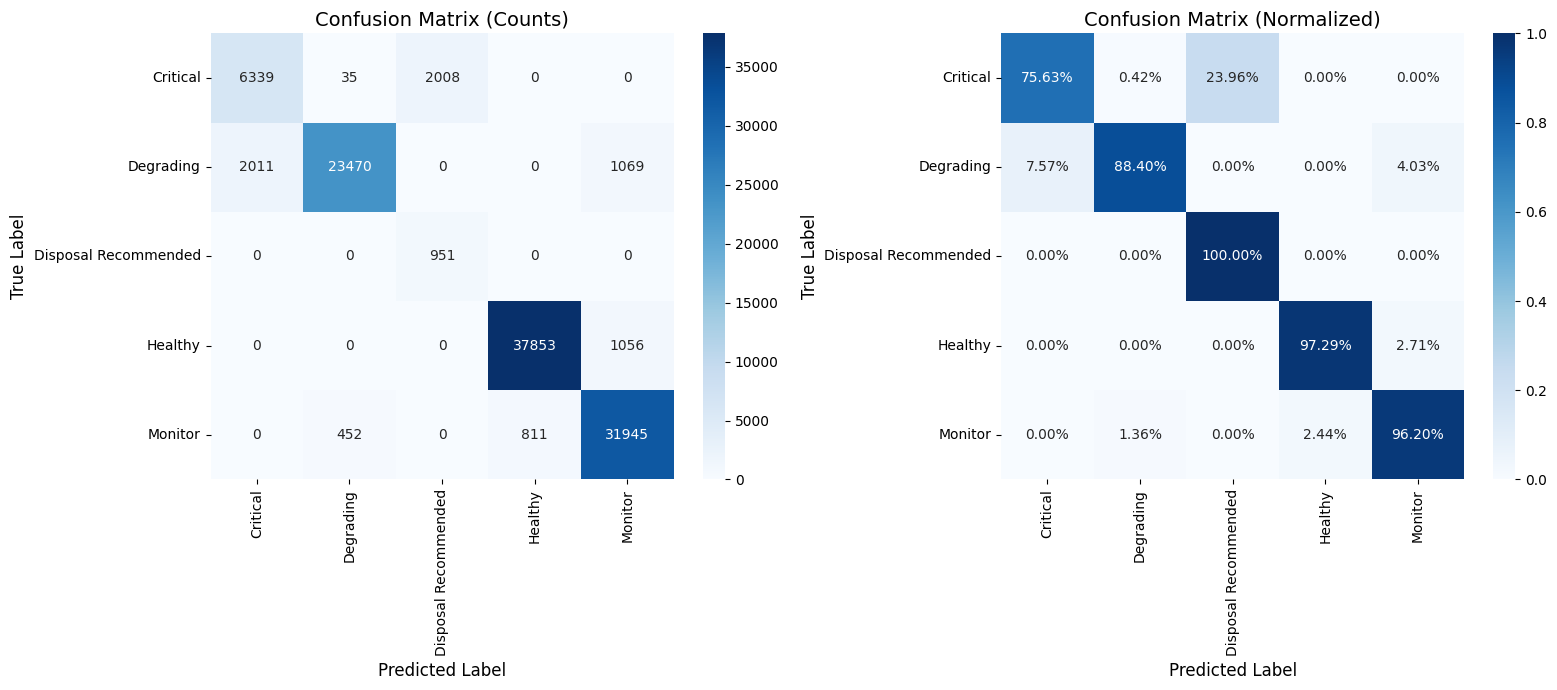

✅ Saved to: training_history_pytorch.png


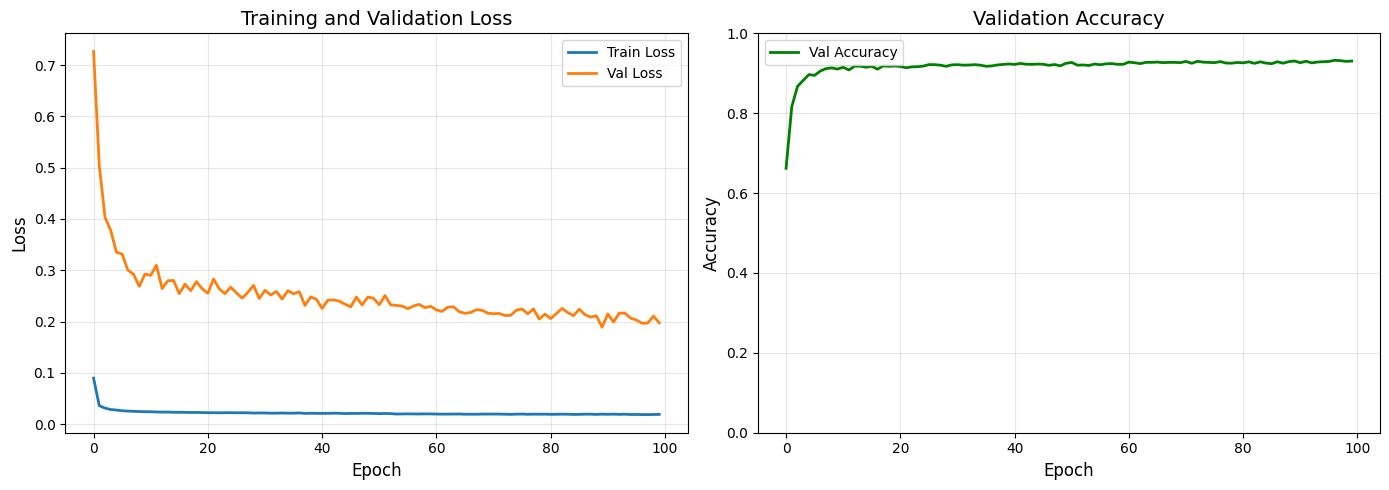


✅ Model saved to: orbitcycle_model.pth

SUMMARY
Test Accuracy: 0.9311 (93.11%)
Test F1-Score: 0.9352

✅ Complete - Model saved as .pth


In [5]:
"""
OrbitCycle - PyTorch Classification for Imbalanced Data
Simplified and corrected version
Model saved as .pth
"""

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


# ============================================================================
# PART 1: SIMPLE NEURAL NETWORK
# ============================================================================

class SatelliteHealthNN(nn.Module):
    """Simple neural network for satellite health classification"""

    def __init__(self, input_dim: int, num_classes: int):
        super(SatelliteHealthNN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# ============================================================================
# PART 2: PYTORCH CLASSIFIER
# ============================================================================

class PyTorchHealthClassifier:
    """Simple PyTorch classifier for imbalanced data"""

    def __init__(self, input_dim: int, num_classes: int,
                 learning_rate: float = 0.001,
                 batch_size: int = 512,
                 epochs: int = 100,
                 random_state: int = 42):

        torch.manual_seed(random_state)
        np.random.seed(random_state)

        self.input_dim = input_dim
        self.num_classes = num_classes
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.device = device

        self.model = None
        self.criterion = None
        self.optimizer = None
        self.scheduler = None
        self.train_losses = []
        self.val_losses = []
        self.val_accuracies = []
        self.class_weights = None

    def _compute_class_weights(self, y_train):
        """Compute class weights for imbalanced data"""
        class_counts = np.bincount(y_train)
        n_samples = len(y_train)
        n_classes = len(class_counts)

        # Standard balanced weights
        balanced_weights = n_samples / (n_classes * class_counts)

        # Find Disposal class (smallest count - typically index 4)
        disposal_idx = np.argmin(class_counts)

        # Boost Disposal weight
        balanced_weights[disposal_idx] = balanced_weights[disposal_idx] * 3.0

        print(f"\nClass counts: {dict(enumerate(class_counts))}")
        print(f"Class weights: {dict(enumerate(np.round(balanced_weights, 3)))}")

        return torch.FloatTensor(balanced_weights).to(self.device)

    def _build_model(self):
        """Build the model"""
        self.model = SatelliteHealthNN(
            input_dim=self.input_dim,
            num_classes=self.num_classes
        ).to(self.device)

        # Use CrossEntropyLoss with class weights
        if self.class_weights is not None:
            self.criterion = nn.CrossEntropyLoss(weight=self.class_weights)
        else:
            self.criterion = nn.CrossEntropyLoss()

        self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', patience=10, factor=0.5
        )

    def train(self, X_train, y_train, X_val=None, y_val=None):
        """Train the model"""

        print("\n" + "=" * 80)
        print("TRAINING PYTORCH CLASSIFIER")
        print("=" * 80)

        # Compute class weights
        self.class_weights = self._compute_class_weights(y_train)

        # Build model
        self._build_model()

        # Convert to tensors
        X_train_tensor = torch.FloatTensor(X_train).to(self.device)
        y_train_tensor = torch.LongTensor(y_train).to(self.device)

        # Create weighted sampler for balanced batches
        sample_weights = np.array([self.class_weights.cpu().numpy()[y] for y in y_train])
        sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

        train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
        train_loader = DataLoader(train_dataset, batch_size=self.batch_size, sampler=sampler)

        # Validation
        has_val = X_val is not None and y_val is not None
        if has_val:
            X_val_tensor = torch.FloatTensor(X_val).to(self.device)
            y_val_tensor = torch.LongTensor(y_val).to(self.device)
            val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
            val_loader = DataLoader(val_dataset, batch_size=self.batch_size, shuffle=False)
            print(f"Validation set: {len(X_val)} samples")

        print(f"\nModel parameters:")
        print(f"  Input dim: {self.input_dim}")
        print(f"  Output classes: {self.num_classes}")
        print(f"  Batch size: {self.batch_size}")
        print(f"  Learning rate: {self.learning_rate}")
        print(f"  Device: {self.device}")

        # Training loop
        best_val_acc = 0
        patience_counter = 0
        patience = 20

        for epoch in range(self.epochs):
            # Training
            self.model.train()
            train_loss = 0
            for batch_X, batch_y in train_loader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                train_loss += loss.item()

            avg_train_loss = train_loss / len(train_loader)
            self.train_losses.append(avg_train_loss)

            # Validation
            if has_val:
                self.model.eval()
                val_loss = 0
                val_correct = 0
                val_total = 0
                val_preds = []
                val_targets = []

                with torch.no_grad():
                    for batch_X, batch_y in val_loader:
                        outputs = self.model(batch_X)
                        loss = self.criterion(outputs, batch_y)
                        val_loss += loss.item()
                        _, predicted = torch.max(outputs, 1)
                        val_total += batch_y.size(0)
                        val_correct += (predicted == batch_y).sum().item()
                        val_preds.extend(predicted.cpu().numpy())
                        val_targets.extend(batch_y.cpu().numpy())

                avg_val_loss = val_loss / len(val_loader)
                val_acc = val_correct / val_total
                val_f1 = f1_score(val_targets, val_preds, average='weighted')

                self.val_losses.append(avg_val_loss)
                self.val_accuracies.append(val_acc)

                # Learning rate scheduling
                self.scheduler.step(avg_val_loss)

                # Save best model
                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    patience_counter = 0
                    self.best_model_state = self.model.state_dict().copy()
                else:
                    patience_counter += 1

                # Print progress (every 10 epochs)
                if (epoch + 1) % 10 == 0:
                    print(f"Epoch [{epoch+1}/{self.epochs}], "
                          f"Train Loss: {avg_train_loss:.4f}, "
                          f"Val Loss: {avg_val_loss:.4f}, "
                          f"Val Acc: {val_acc:.4f}, "
                          f"Val F1: {val_f1:.4f}")

                # Early stopping
                if patience_counter >= patience:
                    print(f"Early stopping at epoch {epoch+1}")
                    self.model.load_state_dict(self.best_model_state)
                    break
            else:
                if (epoch + 1) % 10 == 0:
                    print(f"Epoch [{epoch+1}/{self.epochs}], Train Loss: {avg_train_loss:.4f}")

        print(f"\n✅ Training complete")
        if has_val:
            print(f"   Best validation accuracy: {best_val_acc:.4f}")

        return self.model

    def predict(self, X):
        """Predict class labels"""
        self.model.eval()
        X_tensor = torch.FloatTensor(X).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predictions = torch.max(outputs, 1)

        return predictions.cpu().numpy()

    def predict_proba(self, X):
        """Predict class probabilities"""
        self.model.eval()
        X_tensor = torch.FloatTensor(X).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            probabilities = torch.softmax(outputs, dim=1)

        return probabilities.cpu().numpy()

    def evaluate(self, X_test, y_test, target_names):
        """Evaluate model performance"""

        print("\n" + "=" * 80)
        print("MODEL EVALUATION")
        print("=" * 80)

        y_pred = self.predict(X_test)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred, average='weighted')
        recall = recall_score(y_test, y_pred, average='weighted')
        f1 = f1_score(y_test, y_pred, average='weighted')

        print(f"\n{'Metric':<20} {'Score':<10}")
        print("-" * 35)
        print(f"{'Accuracy':<20} {accuracy:.4f}")
        print(f"{'Precision (weighted)':<20} {precision:.4f}")
        print(f"{'Recall (weighted)':<20} {recall:.4f}")
        print(f"{'F1-Score (weighted)':<20} {f1:.4f}")

        # Per-class metrics
        print("\n" + "-" * 65)
        print("PER-CLASS METRICS")
        print("-" * 65)
        print(classification_report(y_test, y_pred, target_names=target_names))

        # Confusion matrix
        cm = confusion_matrix(y_test, y_pred)

        return {
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'confusion_matrix': cm
        }


# ============================================================================
# PART 3: DATA PREPARATION
# ============================================================================

def load_and_prepare_data(filepath: str):
    """Load dataset"""

    df = pd.read_csv(filepath)
    print(f"\nLoaded {len(df):,} samples")

    # Display label distribution
    print("\nLabel distribution:")
    label_counts = df['health_label'].value_counts()
    for label in ['Healthy', 'Monitor', 'Degrading', 'Critical', 'Disposal Recommended']:
        count = label_counts.get(label, 0)
        pct = count / len(df) * 100
        print(f"  {label}: {count:,} ({pct:.1f}%)")

    return df


def create_features(df: pd.DataFrame):
    """Create features from raw telemetry ONLY"""

    # Raw telemetry features
    feature_columns = [
        'bus_voltage_v',
        'bus_current_a',
        'temperature_c',
        'solar_current_a',
        'battery_voltage_v',
        'battery_temp_c',
        'memory_errors_total',
        'reset_counter_total',
        'altitude_km',
        'orbital_phase'
    ]

    X = df[feature_columns].copy()

    # Handle missing values
    X['altitude_km'] = X['altitude_km'].fillna(X['altitude_km'].median())

    # Add derived features
    X['voltage_temp_ratio'] = X['bus_voltage_v'] / (X['temperature_c'] + 0.1)
    X['current_power'] = X['bus_voltage_v'] * X['bus_current_a']
    X['solar_efficiency'] = X['solar_current_a'] / (X['bus_current_a'] + 0.1)
    X['battery_health'] = X['battery_voltage_v'] / 28.0

    feature_columns.extend(['voltage_temp_ratio', 'current_power', 'solar_efficiency', 'battery_health'])

    # Add orbit type
    le_orbit = LabelEncoder()
    X['orbit_type'] = le_orbit.fit_transform(df['orbit_type'])
    feature_columns.append('orbit_type')

    # Clean data
    X = X.replace([np.inf, -np.inf], np.nan)
    for col in X.columns:
        if X[col].isna().any():
            X[col] = X[col].fillna(X[col].median())

    # Target
    le_target = LabelEncoder()
    y = le_target.fit_transform(df['health_label'])

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    print(f"\nFeatures: {len(feature_columns)} columns")
    print(f"Classes: {le_target.classes_.tolist()}")

    return X_scaled, y, le_target, scaler, feature_columns


# ============================================================================
# PART 4: VISUALIZATION
# ============================================================================

def plot_confusion_matrix(cm, target_names, save_path=None):
    """Plot confusion matrix"""

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names, ax=ax1)
    ax1.set_xlabel('Predicted Label', fontsize=12)
    ax1.set_ylabel('True Label', fontsize=12)
    ax1.set_title('Confusion Matrix (Counts)', fontsize=14)

    # Normalized
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
                xticklabels=target_names, yticklabels=target_names, ax=ax2)
    ax2.set_xlabel('Predicted Label', fontsize=12)
    ax2.set_ylabel('True Label', fontsize=12)
    ax2.set_title('Confusion Matrix (Normalized)', fontsize=14)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✅ Saved to: {save_path}")

    plt.show()


def plot_training_history(classifier, save_path=None):
    """Plot training history"""

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    ax1.plot(classifier.train_losses, label='Train Loss', linewidth=2)
    if classifier.val_losses:
        ax1.plot(classifier.val_losses, label='Val Loss', linewidth=2)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training and Validation Loss', fontsize=14)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Accuracy
    if classifier.val_accuracies:
        ax2.plot(classifier.val_accuracies, label='Val Accuracy', linewidth=2, color='green')
        ax2.set_xlabel('Epoch', fontsize=12)
        ax2.set_ylabel('Accuracy', fontsize=12)
        ax2.set_title('Validation Accuracy', fontsize=14)
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_ylim([0, 1])

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✅ Saved to: {save_path}")

    plt.show()


# ============================================================================
# PART 5: PREDICTOR CLASS
# ============================================================================

class OrbitCyclePredictor:
    """Production predictor with .pth model"""

    def __init__(self, model_path: str = 'orbitcycle_model.pth'):
        self.model = None
        self.label_encoder = None
        self.scaler = None
        self.feature_columns = None
        self.input_dim = None
        self.num_classes = None
        self.device = device
        self.load_model(model_path)

    def load_model(self, model_path: str):
        """Load PyTorch .pth model"""
        checkpoint = torch.load(model_path, map_location=self.device)

        self.label_encoder = checkpoint['label_encoder']
        self.scaler = checkpoint['scaler']
        self.feature_columns = checkpoint['feature_columns']
        self.input_dim = checkpoint['input_dim']
        self.num_classes = checkpoint['num_classes']

        # Rebuild model
        self.model = SatelliteHealthNN(
            input_dim=self.input_dim,
            num_classes=self.num_classes
        ).to(self.device)

        self.model.load_state_dict(checkpoint['model_state_dict'])
        self.model.eval()

        print(f"✅ Model loaded from {model_path}")
        print(f"   Features: {self.input_dim}")
        print(f"   Classes: {self.num_classes}")

    def predict(self, telemetry_df: pd.DataFrame) -> pd.DataFrame:
        """Predict health label from raw telemetry"""

        # Prepare features
        X = telemetry_df[self.feature_columns].copy()
        X = X.replace([np.inf, -np.inf], np.nan)
        for col in X.columns:
            if X[col].isna().any():
                X[col] = X[col].fillna(X[col].median())

        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            probabilities = torch.softmax(outputs, dim=1)
            _, predictions = torch.max(outputs, 1)

        results = telemetry_df.copy()
        results['predicted_label'] = self.label_encoder.inverse_transform(predictions.cpu().numpy())
        results['confidence'] = probabilities.max(dim=1)[0].cpu().numpy()

        for i, class_name in enumerate(self.label_encoder.classes_):
            results[f'prob_{class_name}'] = probabilities[:, i].cpu().numpy()

        return results


# ============================================================================
# PART 6: MAIN - CORRECTED
# ============================================================================

def main():

    print("=" * 80)
    print("ORBITCYCLE - PYTORCH CLASSIFIER (.pth)")
    print("=" * 80)

    # Load data
    filepath = 'orbitcycle_physics_based.csv'
    df = load_and_prepare_data(filepath)

    # Prepare features
    X, y, le_target, scaler, feature_names = create_features(df)

    # Split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.15, random_state=42, stratify=y_train
    )

    print(f"\nData split:")
    print(f"  Training: {len(X_train):,}")
    print(f"  Validation: {len(X_val):,}")
    print(f"  Test: {len(X_test):,}")

    # Train model
    classifier = PyTorchHealthClassifier(
        input_dim=X.shape[1],
        num_classes=len(le_target.classes_),
        learning_rate=0.001,
        batch_size=512,
        epochs=100
    )

    classifier.train(X_train, y_train, X_val, y_val)

    # Evaluate
    results = classifier.evaluate(X_test, y_test, le_target.classes_.tolist())

    # Visualizations
    plot_confusion_matrix(results['confusion_matrix'], le_target.classes_.tolist(),
                         save_path='confusion_matrix_pytorch.png')

    plot_training_history(classifier, save_path='training_history_pytorch.png')

    # Save model (.pth format)
    torch.save({
        'model_state_dict': classifier.model.state_dict(),
        'label_encoder': le_target,
        'scaler': scaler,
        'feature_columns': feature_names,
        'input_dim': X.shape[1],
        'num_classes': len(le_target.classes_)
    }, 'orbitcycle_model.pth')

    print("\n✅ Model saved to: orbitcycle_model.pth")

    # Summary
    print("\n" + "=" * 80)
    print("SUMMARY")
    print("=" * 80)
    print(f"Test Accuracy: {results['accuracy']:.4f} ({results['accuracy']*100:.2f}%)")
    print(f"Test F1-Score: {results['f1']:.4f}")

    return classifier, results


if __name__ == "__main__":
    classifier, results = main()

    print("\n" + "=" * 80)
    print("✅ Complete - Model saved as .pth")
    print("=" * 80)